# 03 · Evaluation, Feature Importance und Fairness

**Ziel:** Modell bewerten, Schwellwert wählen, Treiber interpretieren und Fairness prüfen.  
**Input:** `Modell aus Notebook 02`  
**Output:** `data/processed/dashboard_export.csv`

In [1]:
# Standard setup — run first
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import joblib
import json

from sonnenfeld import config, plotting, modelling

plotting.set_style()
pd.set_option("display.max_columns", 50)

# Load data and recreate the identical test split (same rows as in notebook 02)
df = pd.read_csv(config.INPUT_FILE)
df_model = df.dropna(subset=["zufriedenheit"])

meta = json.load(open(config.MODELS / "modell_final_meta.json"))
modell_final = joblib.load(config.MODELS / "modell_final.joblib")
schwellenwert = meta["schwellenwert"]

merkmale_roh = ["zufriedenheit", "abteilung", "betriebszugehoerigkeit_monate",
                "position", "ueberstunden_monat", "abwesenheitstage_jahr", "gehalt_final"]
_, X_test, _, y_test = modelling.split(df_model, merkmale_roh)

# Same threshold features as in training
X_test = X_test.assign(
    unzufrieden=(X_test["zufriedenheit"] <= 2).astype(int),
    ueberstunden_sehr_hoch=(X_test["ueberstunden_monat"] >= 12).astype(int),
)

## 1. Metriken: Recall, Precision, F1, ROC-AUC

In [2]:
from sklearn.metrics import (recall_score, precision_score, f1_score,
                             roc_auc_score, accuracy_score)

# Predicted probabilities and decisions with the chosen threshold (not the default 0.5)
proba_test = modell_final.predict_proba(X_test)[:, 1]
y_pred_test = (proba_test >= schwellenwert).astype(int)

grundrate = y_test.mean()
precision_test = precision_score(y_test, y_pred_test)

# Test results next to the expectation from cross-validation (notebook 02, section 10)
vergleich = pd.DataFrame({
    "Erwartung (CV)": {"Recall": 0.700, "Precision": 0.306, "Als Risiko markiert": 0.387},
    "Test": {
        "Recall": recall_score(y_test, y_pred_test),
        "Precision": precision_test,
        "Als Risiko markiert": y_pred_test.mean(),
    },
})

with pd.option_context("display.float_format", "{:.1%}".format):
    display(vergleich)

print(f"ROC-AUC:  {roc_auc_score(y_test, proba_test):.3f}")
print(f"F1:       {f1_score(y_test, y_pred_test):.3f}")
print(f"Accuracy: {accuracy_score(y_test, y_pred_test):.1%}")
print(f"Lift:     {precision_test / grundrate:.2f} (Grundrate {grundrate:.1%})")

,Erwartung (CV),Test
Recall,70.0%,66.4%
Precision,30.6%,29.8%
Als Risiko markiert,38.7%,37.6%


ROC-AUC:  0.727
F1:       0.411
Accuracy: 67.9%
Lift:     1.76 (Grundrate 16.9%)


**Erkenntnis 1 (Testdaten, einmalige Bewertung):** Auf den Testdaten erkennt das finale Modell
66,4 % der Kündigungen (Recall) bei einer Precision von 29,8 %; 37,6 % der Mitarbeitenden werden
als Risiko eingestuft. Der ROC-AUC beträgt 0,727, der Lift 1,76.
Das Ziel von 70 % Recall wird auf den Testdaten knapp verfehlt; die Abweichung liegt jedoch
innerhalb der statistischen Unsicherheit (95-%-KI für den Recall bei 321 Kündigungen:
ca. 61–72 %). Alle Kennzahlen entsprechen weitgehend den Erwartungen aus der Kreuzvalidierung.
Das Modell generalisiert damit auf neue Daten; der Schwellenwert wird nicht nachträglich angepasst.

## 2. Konfusionsmatrix und Schwellwert

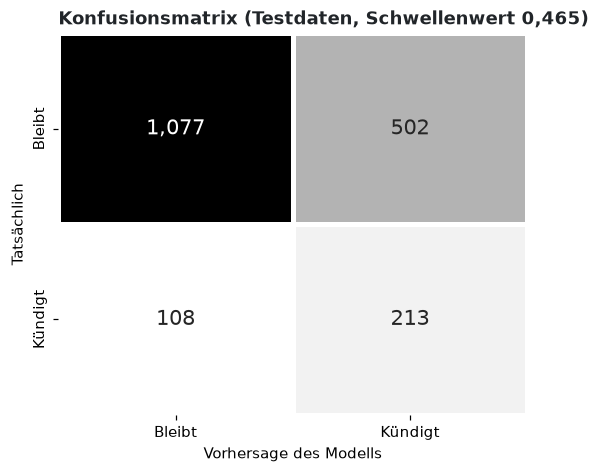

Richtig erkannt (TP): 213 | Übersehen (FN): 108 | Fehlalarme (FP): 502 | Richtig unauffällig (TN): 1077


In [3]:
from sklearn.metrics import confusion_matrix

# Confusion matrix on the test data (rows = reality, columns = prediction)
cm = confusion_matrix(y_test, y_pred_test)
labels = ["Bleibt", "Kündigt"]

fig, ax = plt.subplots(figsize=(5.5, 4.5))
sns.heatmap(
    cm, annot=True, fmt=",d", cmap="Greys", cbar=False,
    xticklabels=labels, yticklabels=labels,
    linewidths=2, linecolor="white", annot_kws={"size": 14}, ax=ax,
)
ax.set_xlabel("Vorhersage des Modells")
ax.set_ylabel("Tatsächlich")
ax.set_title("Konfusionsmatrix (Testdaten, Schwellenwert 0,465)")

plotting.save(fig, "03_konfusionsmatrix")
plt.show()

tn, fp, fn, tp = cm.ravel()
print(f"Richtig erkannt (TP): {tp} | Übersehen (FN): {fn} | Fehlalarme (FP): {fp} | Richtig unauffällig (TN): {tn}")

**Erkenntnis 2:** Von 321 tatsächlichen Kündigungen im Testdatensatz erkennt das Modell 213;
108 werden übersehen. Dem stehen 502 Fehlalarme gegenüber (rund 2,4 pro erkannter Kündigung).
Damit stuft das Modell 66 % der kündigenden, aber nur 32 % der bleibenden Mitarbeitenden als
Risiko ein. Für den Einsatz in Gruppengesprächen ist dieses Verhältnis vertretbar, da ein
Fehlalarm lediglich ein zusätzliches Gespräch bedeutet und keine Einzelperson markiert wird.

## 3. Feature Importance — geschäftlich plausibel?

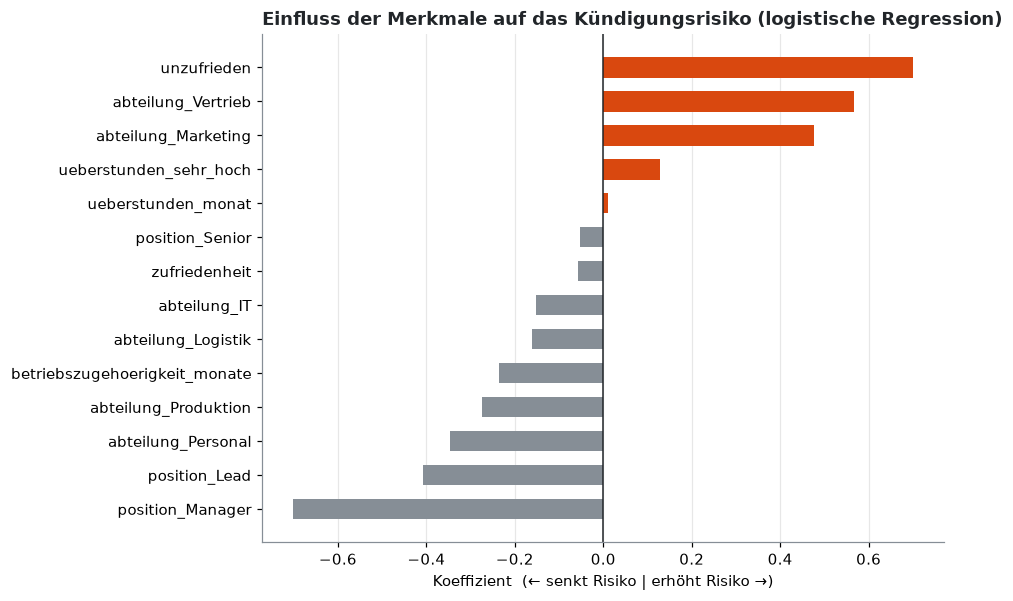

,merkmal,koeffizient,odds_ratio
3,unzufrieden,0.70,2.02
10,abteilung_Vertrieb,0.57,1.76
7,abteilung_Marketing,0.48,1.61
4,ueberstunden_sehr_hoch,0.13,1.14
2,ueberstunden_monat,0.01,1.01
13,position_Senior,-0.05,0.95
0,zufriedenheit,-0.06,0.94
5,abteilung_IT,-0.15,0.86
6,abteilung_Logistik,-0.16,0.85
1,betriebszugehoerigkeit_monate,-0.24,0.79


In [4]:
# Coefficients of the final logistic regression, with odds ratios
namen = modell_final.named_steps["prep"].get_feature_names_out()
koef = modell_final.named_steps["model"].coef_[0]

koeffizienten = pd.DataFrame({
    "merkmal": [n.split("__", 1)[1] for n in namen],   # drop the "num__" / "cat__" prefix
    "koeffizient": koef,
    "odds_ratio": np.exp(koef),
}).sort_values("koeffizient")

fig, ax = plt.subplots(figsize=(8, 6))
farben = [plotting.COLORS["accent"] if k > 0 else plotting.COLORS["neutral"]
          for k in koeffizienten["koeffizient"]]
ax.barh(koeffizienten["merkmal"], koeffizienten["koeffizient"], color=farben, height=0.6)
ax.axvline(0, color=plotting.COLORS["dark"], linewidth=1)
ax.set_title("Einfluss der Merkmale auf das Kündigungsrisiko (logistische Regression)")
ax.set_xlabel("Koeffizient  (← senkt Risiko | erhöht Risiko →)")
ax.grid(axis="x", alpha=0.3)
ax.set_axisbelow(True)

plotting.save(fig, "03_koeffizienten")
plt.show()

with pd.option_context("display.float_format", "{:.2f}".format):
    display(koeffizienten.sort_values("koeffizient", ascending=False))

In [5]:
# Coefficients of scaled features refer to one standard deviation.
# For the binary threshold features, convert to the effect of 0 -> 1 (exact, no refitting).
scaler = modell_final.named_steps["prep"].named_transformers_["num"]
std_je_merkmal = dict(zip(scaler.feature_names_in_, scaler.scale_))

def koef_pro_einheit(row):
    if row["merkmal"] in ["unzufrieden", "ueberstunden_sehr_hoch"]:
        return row["koeffizient"] / std_je_merkmal[row["merkmal"]]
    return row["koeffizient"]

koeffizienten["koef_interpretierbar"] = koeffizienten.apply(koef_pro_einheit, axis=1)
koeffizienten["odds_ratio"] = np.exp(koeffizienten["koef_interpretierbar"])

with pd.option_context("display.float_format", "{:.2f}".format):
    display(koeffizienten.sort_values("koef_interpretierbar", ascending=False))

,merkmal,koeffizient,odds_ratio,koef_interpretierbar
3,unzufrieden,0.70,4.88,1.59
10,abteilung_Vertrieb,0.57,1.76,0.57
7,abteilung_Marketing,0.48,1.61,0.48
4,ueberstunden_sehr_hoch,0.13,1.57,0.45
2,ueberstunden_monat,0.01,1.01,0.01
13,position_Senior,-0.05,0.95,-0.05
0,zufriedenheit,-0.06,0.94,-0.06
5,abteilung_IT,-0.15,0.86,-0.15
6,abteilung_Logistik,-0.16,0.85,-0.16
1,betriebszugehoerigkeit_monate,-0.24,0.79,-0.24


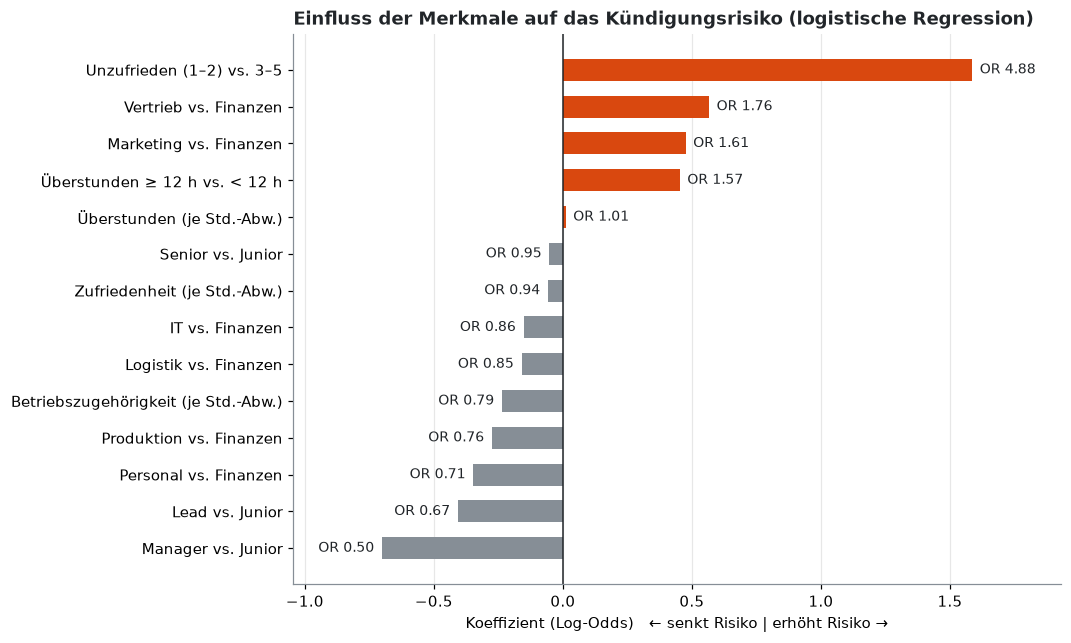

In [6]:
# Readable labels: state the unit / reference of each effect
beschriftung = {
    "unzufrieden": "Unzufrieden (1–2) vs. 3–5",
    "ueberstunden_sehr_hoch": "Überstunden ≥ 12 h vs. < 12 h",
    "ueberstunden_monat": "Überstunden (je Std.-Abw.)",
    "zufriedenheit": "Zufriedenheit (je Std.-Abw.)",
    "betriebszugehoerigkeit_monate": "Betriebszugehörigkeit (je Std.-Abw.)",
    "abteilung_IT": "IT vs. Finanzen",
    "abteilung_Logistik": "Logistik vs. Finanzen",
    "abteilung_Marketing": "Marketing vs. Finanzen",
    "abteilung_Personal": "Personal vs. Finanzen",
    "abteilung_Produktion": "Produktion vs. Finanzen",
    "abteilung_Vertrieb": "Vertrieb vs. Finanzen",
    "position_Senior": "Senior vs. Junior",
    "position_Lead": "Lead vs. Junior",
    "position_Manager": "Manager vs. Junior",
}

plot_df = koeffizienten.sort_values("koef_interpretierbar")
labels = plot_df["merkmal"].map(beschriftung)
farben = [plotting.COLORS["accent"] if k > 0 else plotting.COLORS["neutral"]
          for k in plot_df["koef_interpretierbar"]]

fig, ax = plt.subplots(figsize=(9, 6.5))
ax.barh(labels, plot_df["koef_interpretierbar"], color=farben, height=0.6)
ax.axvline(0, color=plotting.COLORS["dark"], linewidth=1)

# Odds ratio next to each bar (outside the bar end)
for y, (k, odds) in enumerate(zip(plot_df["koef_interpretierbar"], plot_df["odds_ratio"])):
    ax.annotate(f"OR {odds:.2f}", (k, y),
                xytext=(5 if k >= 0 else -5, 0), textcoords="offset points",
                ha="left" if k >= 0 else "right", va="center",
                color=plotting.COLORS["dark"], fontsize=9)

ax.set_title("Einfluss der Merkmale auf das Kündigungsrisiko (logistische Regression)")
ax.set_xlabel("Koeffizient (Log-Odds)   ← senkt Risiko | erhöht Risiko →")
ax.margins(x=0.15)
ax.grid(axis="x", alpha=0.3)
ax.set_axisbelow(True)

plotting.save(fig, "03_koeffizienten")
plt.show()

**Erkenntnis 3 (Merkmalseinfluss):** Unzufriedenheit ist das Merkmal mit dem stärksten
Zusammenhang zum Kündigungsrisiko. Mitarbeitende mit Zufriedenheit 1–2 haben eine rund 4,9-fach
höhere Chance (Odds) einer Kündigung als Mitarbeitende mit Zufriedenheit 3–5. Dieses Ergebnis
wird durch drei unabhängige Betrachtungen gestützt: den höchsten Chi-Quadrat-Wert der EDA
(χ² = 841), das höchste Odds Ratio im Modell (4,9) sowie die Übereinstimmung mit dem
unbereinigten Odds Ratio aus den Rohdaten (4,8).
Es folgen die Abteilungen Vertrieb (Odds Ratio 1,76) und Marketing (1,61) im Vergleich zu
Finanzen sowie sehr hohe Überstunden (≥ 12 h; 1,57).
Risikomindernd wirken höhere Hierarchieebenen (Manager 0,50, Lead 0,67 im Vergleich zu Junior)
und eine längere Betriebszugehörigkeit (0,79 je Standardabweichung).
Die stetigen Merkmale Zufriedenheit und Überstunden tragen neben den Schwellenwerten kaum bei,
was die in der EDA festgestellten Schwelleneffekte bestätigt. Alle Effekte sind geschäftlich
plausibel und stimmen mit der EDA überein.

Methodische Hinweise:
- Da die binären Merkmale standardisiert in das Modell eingingen, wurden ihre Koeffizienten zur
  Interpretation auf eine Veränderung von 0 auf 1 umgerechnet (Koeffizient / Standardabweichung).
- Odds Ratios binärer Merkmale (0 → 1) und stetiger Merkmale (je Standardabweichung) sind nur
  eingeschränkt direkt vergleichbar. Angesichts des großen Abstands ändert dies die Rangfolge
  nicht; eine skalenunabhängige Prüfung wäre z. B. per Permutation Importance möglich.
- Odds Ratios beschreiben relative Chancen, keine Kündigungswahrscheinlichkeiten, und sind als
  Zusammenhänge, nicht als Ursachen zu interpretieren.

Ausblick: Die Betriebszugehörigkeit geht linear ein; ein Merkmal „< 2 Jahre" könnte den in der EDA
beobachteten Effekt der ersten Jahre besser abbilden.

## 4. Fairness-Prüfung nach geschlecht

### 4.1 Testdaten

In [7]:
# Gender of the test employees (same rows via the index; gender was never a model input)
geschlecht_test = df_model.loc[X_test.index, "geschlecht"]

def fairness_tabelle(y_true, y_pred, gruppe):
    """Recall, false positive rate and flagged share per group, with group sizes and 95 % CI for recall."""
    zeilen = {}
    for g in sorted(gruppe.unique()):
        maske = gruppe == g
        yt, yp = y_true[maske], y_pred[maske]
        n_pos, n_neg = (yt == 1).sum(), (yt == 0).sum()
        recall = ((yp == 1) & (yt == 1)).sum() / n_pos
        fpr = ((yp == 1) & (yt == 0)).sum() / n_neg
        ki = 1.96 * np.sqrt(recall * (1 - recall) / n_pos)
        zeilen[g] = {
            "n": maske.sum(), "Kündigungen": n_pos,
            "Recall": recall, "Recall KI ±": ki,
            "FPR": fpr, "Anteil markiert": yp.mean(),
        }
    return pd.DataFrame(zeilen).T

fair = fairness_tabelle(y_test.values, y_pred_test, geschlecht_test.values)
with pd.option_context("display.float_format", "{:.2f}".format):
    display(fair)

,n,Kündigungen,Recall,Recall KI ±,FPR,Anteil markiert
divers,63.00,3.00,0.33,0.53,0.27,0.27
männlich,991.00,164.00,0.66,0.07,0.33,0.38
weiblich,846.00,154.00,0.67,0.07,0.31,0.38


**Zwischenergebnis (Testdaten):** Für Frauen und Männer arbeitet das Modell gleichwertig
(Recall 67 % bzw. 66 %, jeweils ± 7 Prozentpunkte; Falsch-Positiv-Rate 31 % bzw. 33 %).
Für die Gruppe „divers" (n = 63) liegen im Testdatensatz nur 3 Kündigungen vor; der Recall ist
damit nicht belastbar auswertbar. Um auch diese Gruppe beurteilen zu können, wird die Prüfung
in Abschnitt 4.2 um die Out-of-Fold-Vorhersagen der Trainingsdaten erweitert.

### 4.2 Erweiterte Prüfung (n = 9500)

In [8]:
# Load the out-of-fold probabilities saved in notebook 02
oof = pd.read_csv(config.DATA_PROCESSED / "oof_vorhersagen.csv", index_col=0)

# Turn probabilities into decisions with the same threshold as the final model
oof["vorhersage"] = (oof["proba"] >= schwellenwert).astype(int)

# Add gender via the row index (gender was never a model input)
oof["geschlecht"] = df_model.loc[oof.index, "geschlecht"]

oof.head()

,proba,gekuendigt,vorhersage,geschlecht
2943,0.271714,0,0,männlich
4342,0.711658,0,1,männlich
8379,0.220236,0,0,weiblich
6715,0.304697,0,0,männlich
5167,0.403194,1,0,weiblich


In [9]:
# Test predictions in the same format as the out-of-fold table
test = pd.DataFrame(
    {"gekuendigt": y_test.values, "vorhersage": y_pred_test, "geschlecht": geschlecht_test.values},
    index=X_test.index,
)

# Combine: 7,600 out-of-fold + 1,900 test = 9,500 employees, all scored by a model that never saw them
gesamt = pd.concat([oof[["gekuendigt", "vorhersage", "geschlecht"]], test])
print("Mitarbeitende gesamt:", len(gesamt))

# Same fairness function as before, now on all 9,500
fair_gesamt = fairness_tabelle(
    gesamt["gekuendigt"].values, gesamt["vorhersage"].values, gesamt["geschlecht"].values
)
with pd.option_context("display.float_format", "{:.2f}".format):
    display(fair_gesamt)

Mitarbeitende gesamt: 9500


,n,Kündigungen,Recall,Recall KI ±,FPR,Anteil markiert
divers,286.00,48.00,0.67,0.13,0.30,0.36
männlich,4946.00,810.00,0.68,0.03,0.32,0.38
weiblich,4268.00,747.00,0.70,0.03,0.32,0.39


**Erkenntnis 4 (Fairness-Prüfung):** Um auch die kleine Gruppe „divers" belastbar auswerten
zu können, wurden die Out-of-Fold-Vorhersagen der Trainingsdaten (n = 7.600) mit den
Testvorhersagen (n = 1.900) zusammengeführt. Alle 9.500 Vorhersagen stammen von Modellen, die
die jeweilige Person nicht im Training gesehen haben.
Das Modell arbeitet für alle drei Gruppen gleichwertig: Recall (divers 67 % ± 13, männlich
68 % ± 3, weiblich 70 % ± 3), Falsch-Positiv-Rate (30–32 %) und Anteil als Risiko eingestufter
Mitarbeitender (36–39 %) unterscheiden sich nur geringfügig; die Konfidenzintervalle überlappen.
Obwohl Proxy-Effekte über andere Merkmale möglich wären, gibt es keine Hinweise auf eine
systematische Benachteiligung. Die Entscheidung, `geschlecht` nicht als Modellmerkmal zu
verwenden, wird damit bestätigt.
Einschränkung: Für die Gruppe „divers" bleibt die Unsicherheit wegen der geringen Fallzahl höher.

## 5. Risikosegmente (≥ 10 Personen) und Export für das Dashboard

### 5.1 Risikosegmente

In [10]:
# One risk score per employee: out-of-fold (train) + test, all predicted "unseen"
risikoscore = pd.concat([
    oof["proba"],
    pd.Series(proba_test, index=X_test.index),
])

# Segment dimensions from the original table, matched via the row index
seg = df_model.loc[risikoscore.index, ["abteilung", "position", "betriebszugehoerigkeit_jahre", config.TARGET]].copy()
seg["risikoscore"] = risikoscore
seg["zugehoerigkeit"] = np.where(seg["betriebszugehoerigkeit_jahre"] < 2, "< 2 Jahre", "≥ 2 Jahre")

print(len(seg))
seg.head()

9500


,abteilung,position,betriebszugehoerigkeit_jahre,gekuendigt,risikoscore,zugehoerigkeit
2943,Produktion,Junior,6,0,0.271714,≥ 2 Jahre
4342,Marketing,Senior,13,0,0.711658,≥ 2 Jahre
8379,Produktion,Senior,6,0,0.220236,≥ 2 Jahre
6715,Vertrieb,Manager,3,0,0.304697,≥ 2 Jahre
5167,Personal,Junior,1,1,0.403194,< 2 Jahre


In [11]:
# Aggregate per segment: department × position × tenure group
segmente = (
    seg.groupby(["abteilung", "position", "zugehoerigkeit"])
       .agg(
           anzahl=("risikoscore", "size"),
           risikoscore_mittel=("risikoscore", "mean"),
           anteil_ueber_schwelle=("risikoscore", lambda s: (s >= schwellenwert).mean()),
           beobachtete_quote=(config.TARGET, "mean"),
       )
       .reset_index()
)

# Privacy rule: report only segments with at least 10 employees
MIN_SEGMENTGROESSE = 10
print("Segmente gesamt:", len(segmente))
segmente = segmente[segmente["anzahl"] >= MIN_SEGMENTGROESSE]
print("Segmente ≥ 10 Personen:", len(segmente))

# Decision rule (ML Canvas): segment is flagged if its mean risk score reaches the threshold
segmente["risikosegment"] = segmente["risikoscore_mittel"] >= schwellenwert
print("Davon als Risikosegment markiert:", segmente["risikosegment"].sum())

segmente.sort_values("risikoscore_mittel", ascending=False).head(15)

Segmente gesamt: 56
Segmente ≥ 10 Personen: 55
Davon als Risikosegment markiert: 14


,abteilung,position,zugehoerigkeit,anzahl,risikoscore_mittel,anteil_ueber_schwelle,beobachtete_quote,risikosegment
48,Vertrieb,Junior,< 2 Jahre,316,0.622935,0.996835,0.341772,True
30,Marketing,Senior,< 2 Jahre,145,0.604143,0.903448,0.324138,True
24,Marketing,Junior,< 2 Jahre,222,0.596309,0.995495,0.346847,True
54,Vertrieb,Senior,< 2 Jahre,170,0.595146,1.000000,0.223529,True
55,Vertrieb,Senior,≥ 2 Jahre,397,0.555736,0.604534,0.236776,True
49,Vertrieb,Junior,≥ 2 Jahre,652,0.553107,0.624233,0.182515,True
25,Marketing,Junior,≥ 2 Jahre,500,0.532515,0.482000,0.186000,True
26,Marketing,Lead,< 2 Jahre,69,0.528016,0.362319,0.362319,True
50,Vertrieb,Lead,< 2 Jahre,83,0.525018,0.301205,0.216867,True
31,Marketing,Senior,≥ 2 Jahre,269,0.523145,0.434944,0.171004,True


In [12]:
# Coverage of the flagged segments: share of workforce reached and share of all resignations within them
markiert = segmente[segmente["risikosegment"]]
anteil_belegschaft = markiert["anzahl"].sum() / len(seg)
kuendigungen_markiert = (markiert["anzahl"] * markiert["beobachtete_quote"]).sum()
anteil_kuendigungen = kuendigungen_markiert / seg[config.TARGET].sum()

print(f"Markierte Segmente erreichen {anteil_belegschaft:.1%} der Belegschaft")
print(f"und enthalten {anteil_kuendigungen:.1%} aller Kündigungen")

Markierte Segmente erreichen 35.0% der Belegschaft
und enthalten 47.2% aller Kündigungen


**Erkenntnis 5 (Risikosegmente):** Die 9.500 Vorhersagen wurden zu Segmenten aus Abteilung,
Hierarchieebene und Betriebszugehörigkeit (< 2 / ≥ 2 Jahre) zusammengefasst. Von 56 Segmenten
umfassen 55 mindestens 10 Personen; 14 überschreiten mit ihrem mittleren Risikoscore den
Schwellenwert von 0,465. Die höchsten Risiken zeigen Junior- und Senior-Mitarbeitende in Vertrieb
und Marketing in den ersten zwei Beschäftigungsjahren (tatsächliche Quote 22–35 % gegenüber
16,9 % insgesamt).
Die markierten Segmente erreichen 35 % der Belegschaft und enthalten 47 % aller Kündigungen
(Lift 1,35). Gegenüber der Einzelvorhersage (Lift 1,8) sinkt die Trennschärfe, da Segmente
Personen mit unterschiedlichem Risiko zusammenfassen und die Zufriedenheit zum Schutz der
Anonymität der Mitarbeiterbefragung nicht zur Segmentbildung genutzt wird. Diese geringere
Trefferquote wird zugunsten des Datenschutzes bewusst in Kauf genommen.
Hinweis: Die Risikoscores sind durch die Klassengewichtung nicht kalibriert und dienen der
Rangfolge; kommuniziert werden die tatsächlichen Quoten je Segment.
Empfehlung: Die Zufriedenheit wird ergänzend über die aggregierten, anonymen Ergebnisse der
Mitarbeiterbefragung (z. B. Bottom-2-Box je Abteilung) berücksichtigt.

### 5.2 Export

In [13]:
# Export for the Tableau dashboard: aggregated segments only (>= 10 employees, no individual data)
export = segmente.rename(columns={
    "abteilung": "Abteilung",
    "position": "Hierarchieebene",
    "zugehoerigkeit": "Betriebszugehoerigkeit",
    "anzahl": "Anzahl_Mitarbeitende",
    "risikoscore_mittel": "Risikoscore_Mittel",            # for ranking only, not a probability
    "anteil_ueber_schwelle": "Anteil_ueber_Schwellenwert",
    "beobachtete_quote": "Fluktuationsquote_tatsaechlich",  # the number to communicate
    "risikosegment": "Risikosegment",
}).round(3)

export.to_csv(config.DATA_PROCESSED / "dashboard_export.csv", index=False)
print(f"Exportiert: {len(export)} Segmente, {export['Risikosegment'].sum()} markiert")

Exportiert: 55 Segmente, 14 markiert


## 6. Erkenntnisse und Empfehlungen

## 6. Erkenntnisse und Empfehlungen

### Modell
- Finales Modell: logistische Regression mit binären Schwellenwerten (Zufriedenheit ≤ 2,
  Überstunden ≥ 12 h), ohne Abwesenheitstage; Auswahl per Kreuzvalidierung nach der
  One-Standard-Error-Regel zugunsten der Interpretierbarkeit.
- Testdaten (einmalige Bewertung): Recall 66,4 %, Precision 29,8 %, ROC-AUC 0,727, Lift 1,76.
  Das Ziel von 70 % Recall wird knapp verfehlt, liegt aber innerhalb der statistischen Unsicherheit.
- Gegenüber dem Baseline-Modell (Recall 0 %) erkennt das Modell zwei von drei Kündigungen,
  bei rund 2,4 Fehlalarmen pro erkannter Kündigung.

### Wichtigste Zusammenhänge
- Unzufriedenheit (1–2) ist der stärkste Faktor (Odds Ratio 4,9).
- Vertrieb (1,76) und Marketing (1,61) sowie die ersten zwei Beschäftigungsjahre gehen mit
  erhöhtem Risiko einher; höhere Hierarchieebenen wirken risikomindernd (Manager 0,50).
- Sehr hohe Überstunden (≥ 12 h) erhöhen das Risiko moderat (1,57).
- Kein Zusammenhang: Alter, relatives Gehalt, Abwesenheit.
- Die Faktoren wirken weitgehend unabhängig voneinander.

### Fairness und Datenschutz
- Recall, Falsch-Positiv-Rate und Anteil markierter Personen unterscheiden sich zwischen den
  Geschlechtern nicht nennenswert (n = 9.500, Out-of-Fold- und Testvorhersagen).
- Ergebnisse werden ausschließlich als Segmente mit mindestens 10 Personen weitergegeben.
  14 von 55 Segmenten sind als Risikosegmente markiert; sie umfassen 35 % der Belegschaft und
  47 % der Kündigungen. Die geringere Trennschärfe gegenüber der Einzelvorhersage wird zugunsten
  des Datenschutzes bewusst in Kauf genommen.

### Empfehlungen für die Personalabteilung
1. **Onboarding und Bindung in den ersten zwei Jahren** priorisieren, beginnend mit Junior- und
   Senior-Mitarbeitenden in Vertrieb und Marketing (tatsächliche Quote 22–35 %).
2. **Zufriedenheit als Frühindikator** nutzen: Die Bottom-2-Box (Anteil der Antworten 1–2) je
   Abteilung als feste Kennzahl in die jährliche Auswertung der anonymen Mitarbeiterbefragung
   aufnehmen (nur für Gruppen mit ausreichender Teilnehmerzahl). Mittelfristig quartalsweise
   Pulsbefragungen für eine frühere Erkennung; die Befragung um Dimensionen wie Team, Führung
   und Arbeitsbelastung erweitern.
3. **Arbeitsbelastung beobachten:** Mitarbeitende mit ≥ 12 Überstunden pro Monat gezielt entlasten.
4. **Gehaltsanpassungen innerhalb der Vergleichsgruppen** sind nach diesen Daten kein wirksamer
   Hebel gegen Fluktuation.
5. **Betrieb des Modells:** jährliche Vorhersage zum Stichtag, Freigabe durch den Betriebsrat,
   Monitoring inkl. Fairness-Prüfung bei jedem Durchlauf (verantwortlich: HR-Analytics).

### Ausblick
- Datenbasis erweitern: historische Stichtage, Austrittsdatum, Arbeitszeitmodell (Voll-/Teilzeit),
  interne Kosten pro Neubesetzung.
- Modell weiterentwickeln: Merkmal „< 2 Jahre" für die Betriebszugehörigkeit, Variante nur mit
  Schwellenwertmerkmalen, binäre Merkmale unstandardisiert für direkte Interpretierbarkeit.
- Unterstützung bei hohen Abwesenheiten über das Betriebliche Eingliederungsmanagement
  (§ 167 SGB IX), nicht über das Frühwarnmodell.

Alle Ergebnisse beschreiben Zusammenhänge, keine Ursachen.